# CS6180 HW3: VLM Experiments
## George Lin
### Fall 2026

In [39]:
# Import libraries
# Standard library: timing, wrapping long captions for plots, taking the first n items of a stream
import time
import textwrap
from itertools import islice

# Data + plotting: pandas for result tables, matplotlib for showing images (as in Seven-Steps Step 0)
import pandas as pd
import matplotlib.pyplot as plt

# Model stack: torch runs the network; datasets streams Flickr8k; transformers loads SmolVLM
import torch
from datasets import load_dataset
from transformers import AutoProcessor, AutoModelForImageTextToText

pd.set_option("display.max_colwidth", None)   # show full captions in tables (no "..." truncation)

In [40]:
# Define model, processor, and helper functions (same asapp.py, so the notebook
# evaluates the way as the Gradio app)
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"  # pretrained VLM 
DATASET_ID = "intro/flickr8k"  # image-caption dataset 
CAPTION_PROMPT = "Describe this image in one sentence."  # default caption prompt

# Processor = image preprocessing (resize, split into tiles, normalize -> pixel_values)
#           + tokenizer (text <-> token ids, chat-template tokens)
processor = AutoProcessor.from_pretrained(MODEL_ID)

# Load the pretrained weights once (no fine-tuning). device_map="auto" picks CUDA / Apple MPS / CPU;
# .eval() switches off training-only behaviour such as dropout.
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, device_map="auto").eval()


def ask_image(image, question, max_new_tokens=70):
    """Run one image + question through the VLM. Returns (answer, seconds)."""
    # Guards: return a friendly message instead of crashing on empty input.
    if image is None:
        return "Please upload or select an image first", 0.0
    if not question or not question.strip():
        return "Please enter a question", 0.0
    image = image.convert("RGB")  # uploads may be RGBA/grayscale; model expects RGB

    # Chat-format message: one user turn containing the image and the question.
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": question.strip()},
            ],
        }
    ]

    # One call does it all: insert chat tokens + image placeholder tokens,
    # tokenize the text (input_ids), and preprocess the image (pixel_values).
    # add_generation_prompt=True appends "Assistant:" so the model answers next.
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(
        model.device
    )  # move tensors to the same device as the model

    start = time.perf_counter()  # time only the generation step
    with torch.inference_mode():  # no gradient tracking -> faster, less memory
        # do_sample=False = greedy decoding -> same answer every run (reproducible)
        output = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False
        )

    # generate() returns prompt + answer; slice off the prompt to keep only new tokens.
    tokens = output[0][inputs["input_ids"].shape[-1] :]
    # Token ids -> text; skip_special_tokens drops markers like <end_of_utterance>.
    answer = processor.decode(tokens, skip_special_tokens=True).strip()
    return answer, round(time.perf_counter() - start, 2)


def load_flickr_subset(n=60, split="test"):
    """Stream the first n Flickr8k rows -> list of {id, image, captions}."""
    # streaming=True reads rows one at a time instead of downloading the full dataset.
    ds = load_dataset(DATASET_ID, split=split, streaming=True)
    samples = []
    for i, row in enumerate(islice(ds, n)):
        # This mirror stores 5 human captions per image in caption_0 ... caption_4.
        captions = [row[f"caption_{k}"].strip() for k in range(5)]
        samples.append(
            {"id": i, "image": row["image"].convert("RGB"), "captions": captions}
        )
    return samples  # after the loop, so all n samples are returned

def caption_image(image, max_new_tokens=40):
    """One-sentence caption = ask_image with the default caption prompt (the app's Caption button)."""
    return ask_image(image, CAPTION_PROMPT, max_new_tokens)

# Confirm where the model is running and that it is the 256M-parameter version
print(f"Model loaded on {model.device} | {sum(p.numel() for p in model.parameters())/1e6:.0f}M params")

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 50645.20it/s]

Model loaded on mps:0 | 256M params


In [41]:
# Load 60 Flickr8k images (HW asks for 50-100) and split them:
#   pool     = ids 0-49  -> used for browsing, examples, and testing prompts
#   eval_set = ids 50-59 -> held out, used ONLY for the final 10-image evaluation
N_TOTAL, N_EVAL = 60, 10
samples = load_flickr_subset(N_TOTAL)
pool, eval_set = samples[:N_TOTAL - N_EVAL], samples[N_TOTAL - N_EVAL:]
print(f"Loaded {len(samples)} images -> pool={len(pool)}, held-out eval={len(eval_set)}")
print("Columns used: image + caption_0..caption_4")

Loaded 60 images -> pool=50, held-out eval=10
Columns used: image + caption_0..caption_4


## Load and Inspect 5 dataset examples with human reference captions

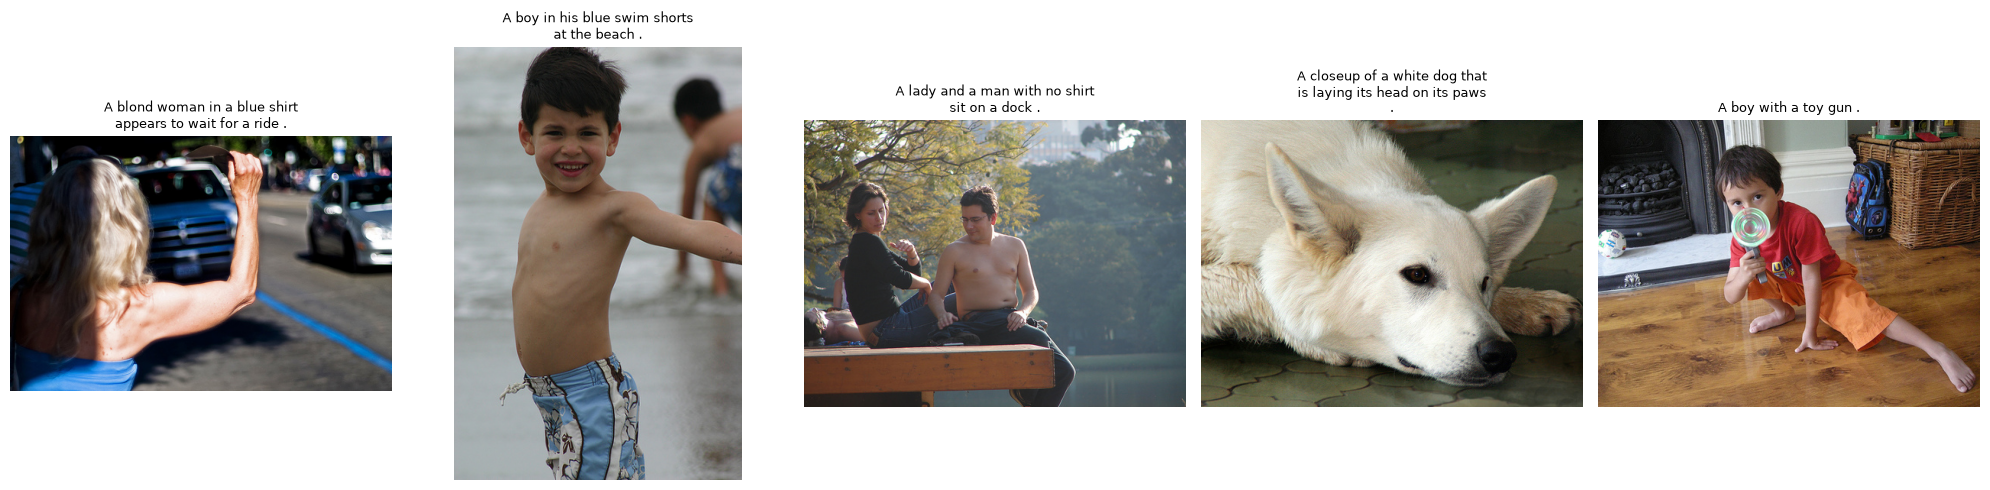

In [42]:
# Show 5 dataset examples with their first human reference caption
fig, axes = plt.subplots(1, 5, figsize=(20, 5))        # 1 row, 5 side-by-side panels
for ax, s in zip(axes, pool[:5]):                       # pair each panel with one sample
    ax.imshow(s["image"])
    ax.axis("off")                                      
    # wrap the caption at ~30 characters so long titles don't overlap neighbours
    ax.set_title("\n".join(textwrap.wrap(s["captions"][0], 30)), fontsize=9)
plt.tight_layout()
plt.show()

## Simple query to test model

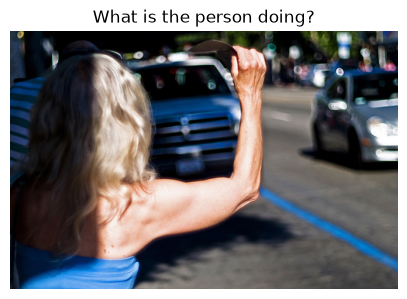

Answer (0.81s): The person is holding a car.
Reference: A blond woman in a blue shirt appears to wait for a ride .


In [43]:
# Sanity check: one image + one question, compared with a human caption
img = pool[0]["image"]                       # first image from the browsing pool (not held out)
question = "What is the person doing?"
answer, secs = ask_image(img, question)      # model answer + generation time in seconds

plt.figure(figsize=(5, 4)); plt.imshow(img); plt.axis("off"); plt.title(question); plt.show()
print(f"Answer ({secs}s): {answer}")
print("Reference:", pool[0]["captions"][0])  # human-written caption from the dataset

## 10-image held-out evaluation: 3 prompt techniques
Each of the 10 held-out images (ids 50–59) is captioned with 3 prompting techniques and compared with its 5 human reference captions. Inference time is recorded automatically; correctness and hallucinations are judged manually.

Techniques adapted from the *Prompt Engineering Lab* 

| | Technique| Idea |
|---|---|---|
| **A** | Zero-shot | Baseline: no guidance on length, focus, or style |
| **B** | Zero-shot, specific + constraints | Spell out the task: one sentence, subject + action + place |
| **C** | Few-shot | Show 3 example captions in Flickr8k style, then ask for one more |


**Techniques tried and dropped** (pilot run on the same images):
- **Role prompting** : *"You are writing captions for a photo dataset…"* made the model role-play. It answered "Hi there!" and "Hi there! I'm hiking up a mountain!"
- **Structured output** : *"Subject: / Action: / Setting:"* was ignored. Answers were single words like "Room." or "Picture."
- **Task decomposition** : numbered sub-questions got partial answers. Usually only #1 was answered, e.g. "The main subject is a dog."

These failures suggest a 256M model follows short, plain instructions and examples better than elaborate formats.

In [47]:
# The 3 prompting techniques. Only the prompt changes;
# model, images, and decoding settings stay fixed so differences come from wording alone.
PROMPTS = {
    # A: zero-shot, vague: no guidance on length, focus, or style (baseline)
    "A_vague": "What is happening in the image?",
    # B: zero-shot, specific + constraints: spell out format (one sentence) and content
    "B_specific": (
        "Describe this image in one sentence. Say who or what the main subject is, include gender, age if applicable "
        "what they are doing, and where they are."
    ),
    # C: few-shot: show the desired caption style with 3 hand-written examples
    #    (not taken from the eval images, so no reference captions leak into the prompt)
    "C_few_shot": (
        "Write a one-sentence caption for this image, in the same style as these examples.\n"
        "Example: A black dog is running through the grass.\n"
        "Example: Two children are playing in the sand at the beach.\n"
        "Example: A man in a red jacket is climbing a snowy mountain.\n"
        "Caption:"
    ),
}

# Simple automatic score: share of the answer's content words found in any of the 5 references.
# Filler words (and the model's habitual "In this image we can see...") are ignored via STOP.
STOP = set("a an the is are in on of with and to at this image i we can see there "
           "they their it its main subject".split())

def content_words(text):
    """Lower-cased set of meaningful words, punctuation stripped, stopwords removed."""
    return {w.strip(".,!?:;\"'").lower() for w in text.split()} - STOP - {""}

def overlap_score(answer, references):
    """Fraction of the answer's content words that appear in ANY of the reference captions (0-1)."""
    words = content_words(answer)
    if not words:
        return 0.0
    ref_words = set().union(*(content_words(r) for r in references))   # merge all 5 references
    return round(len(words & ref_words) / len(words), 2)

# Run all 3 prompts on all 10 held-out images (30 generations, ~25 s on MPS).
# Each generation becomes one row; time is recorded automatically by ask_image.
prompt_rows = []
for s in eval_set:
    for tech, prompt in PROMPTS.items():
        answer, secs = ask_image(s["image"], prompt, max_new_tokens=60)
        prompt_rows.append({
            "id": s["id"], "technique": tech, "answer": answer,
            "words": len(answer.split()), "time_s": secs,
            "overlap": overlap_score(answer, s["captions"]),
            "correct": "", "hallucination": "",      # filled in manually below
        })
prompt_df = pd.DataFrame(prompt_rows)   # long format: 30 rows = 10 images x 3 techniques
print(f"{len(prompt_df)} generations done")

30 generations done


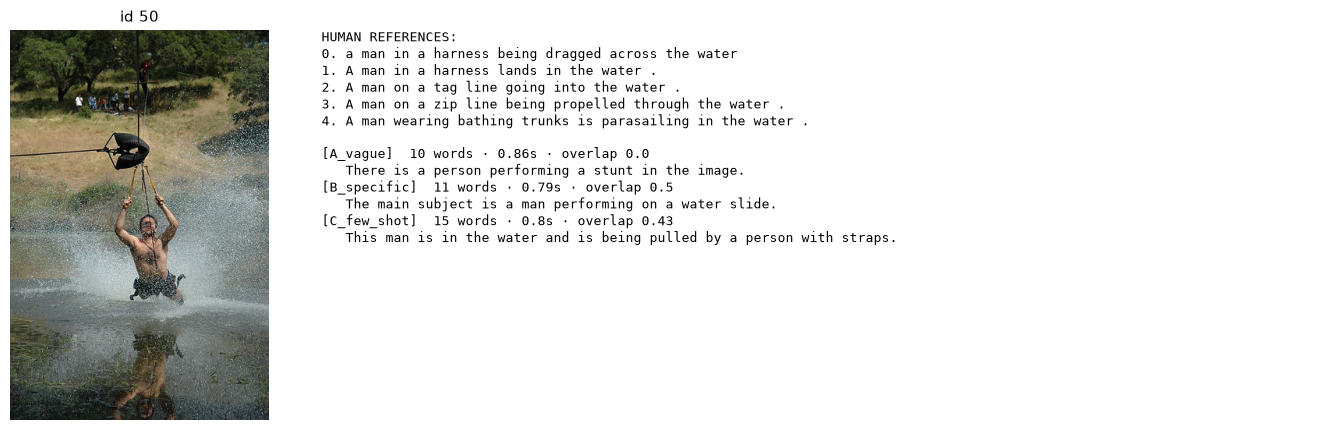

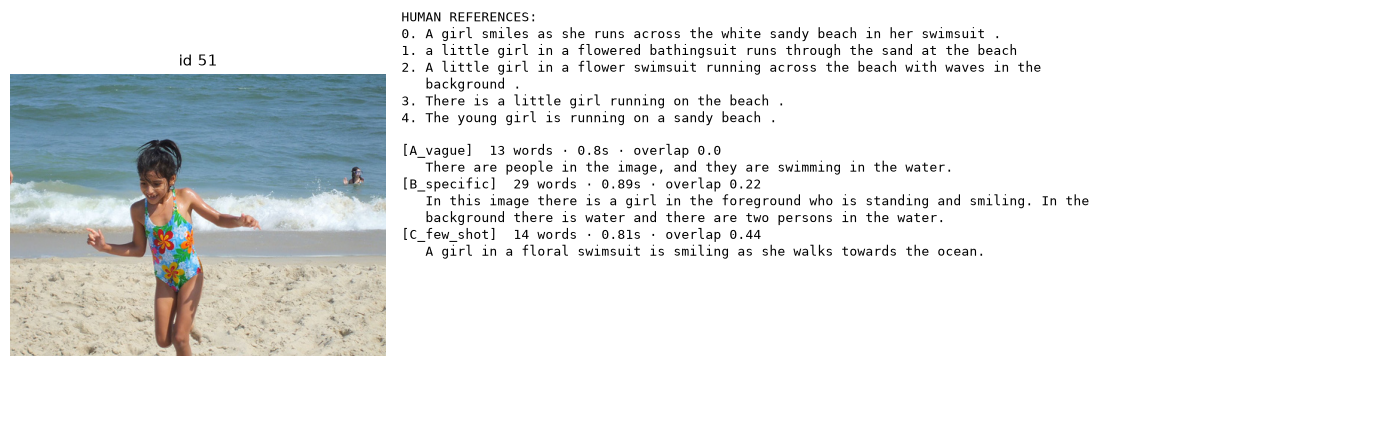

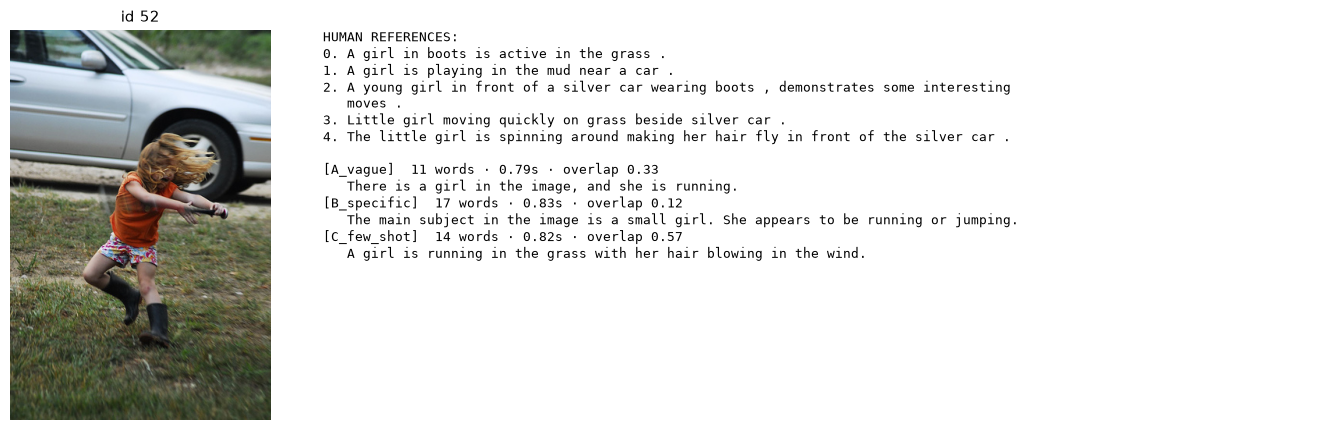

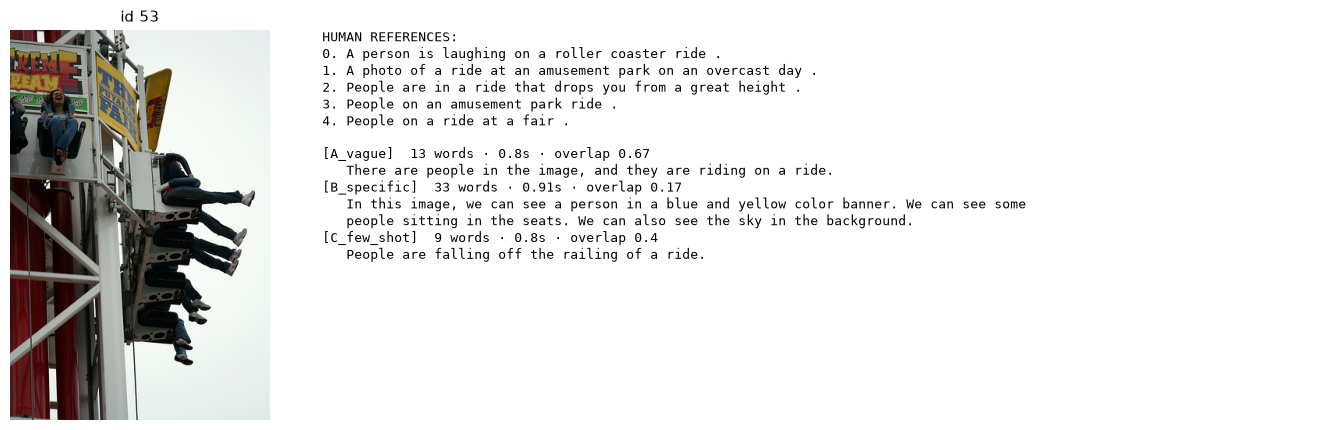

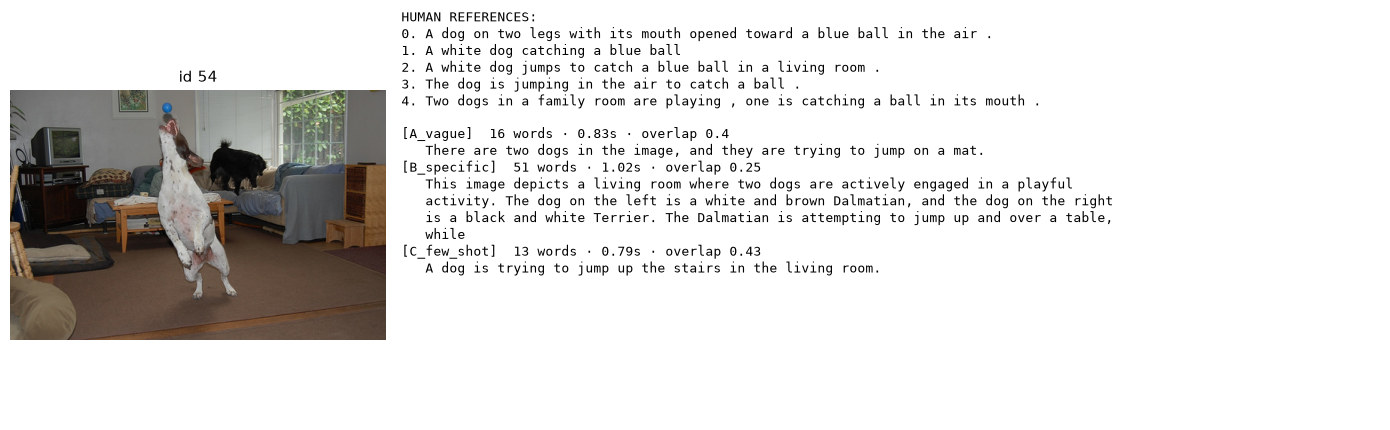

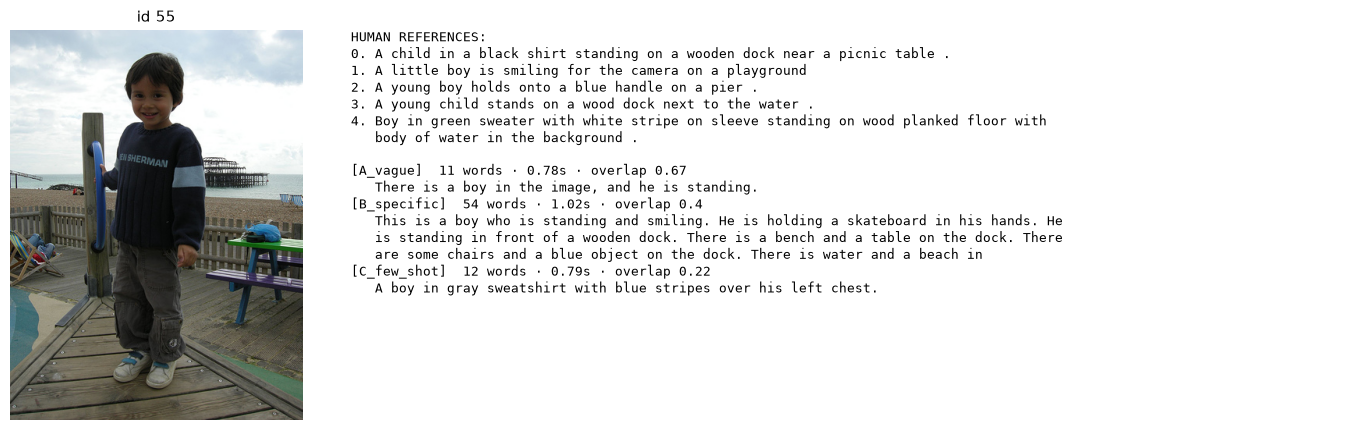

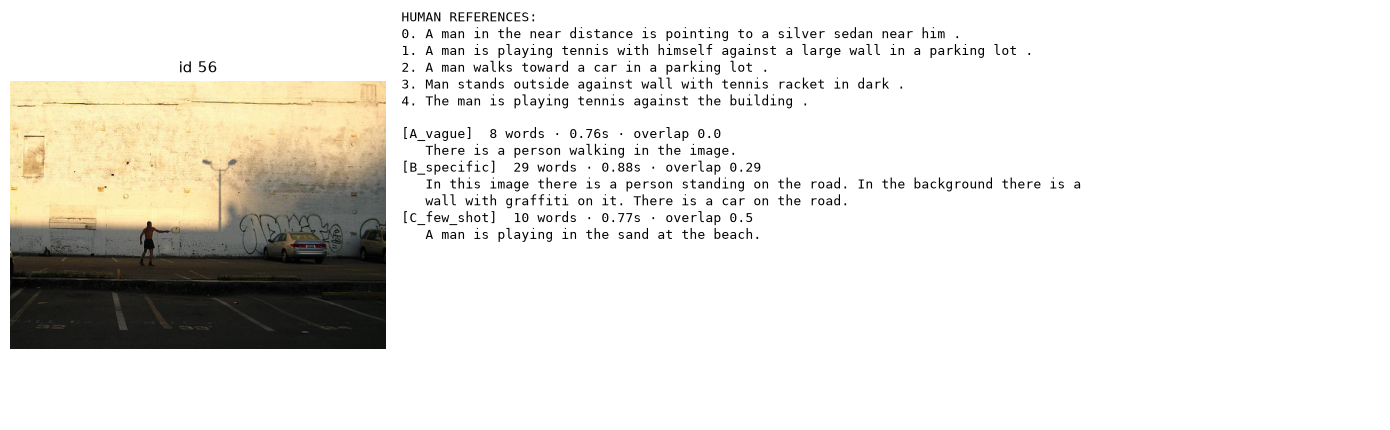

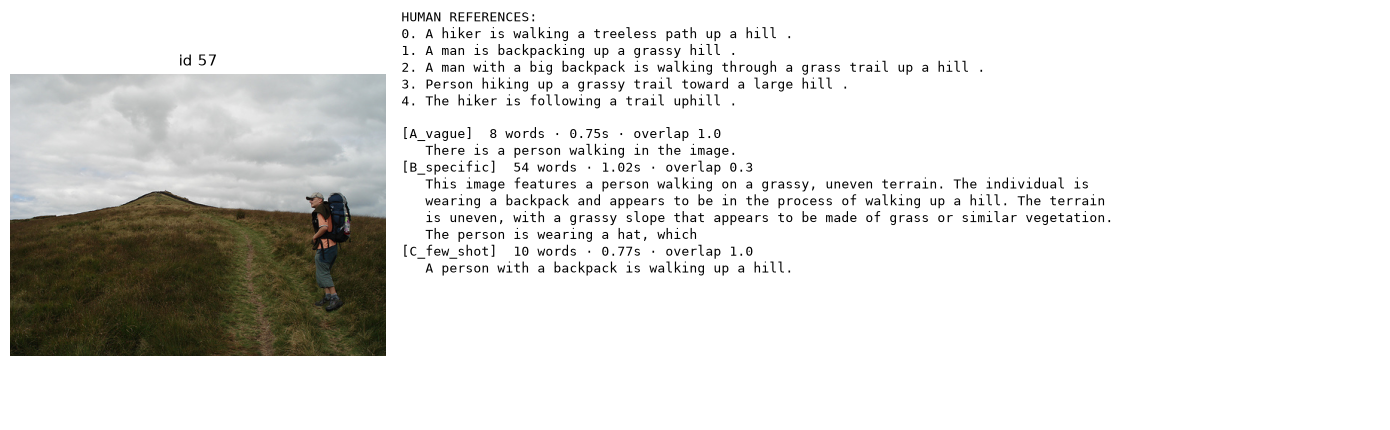

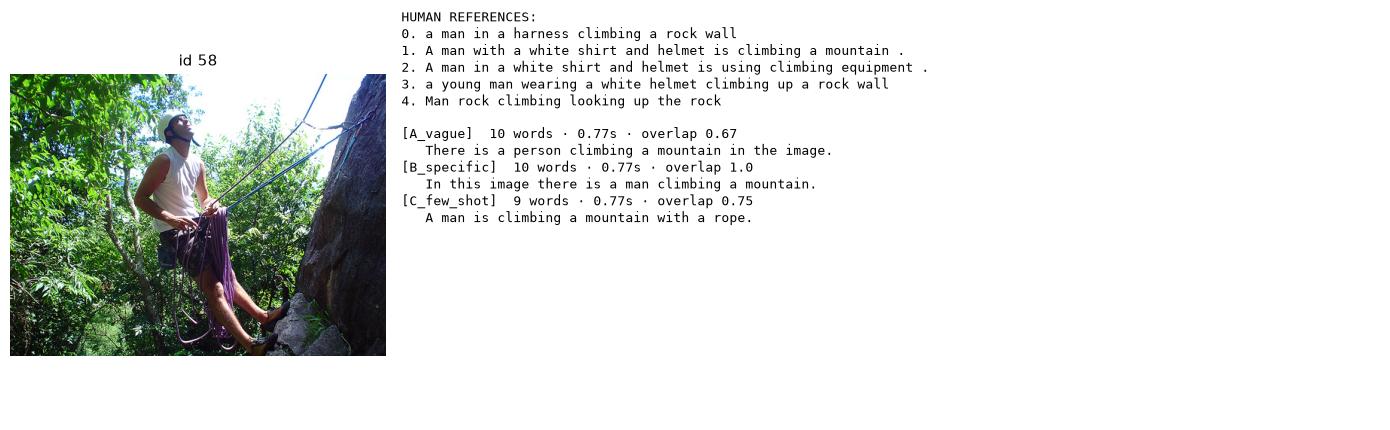

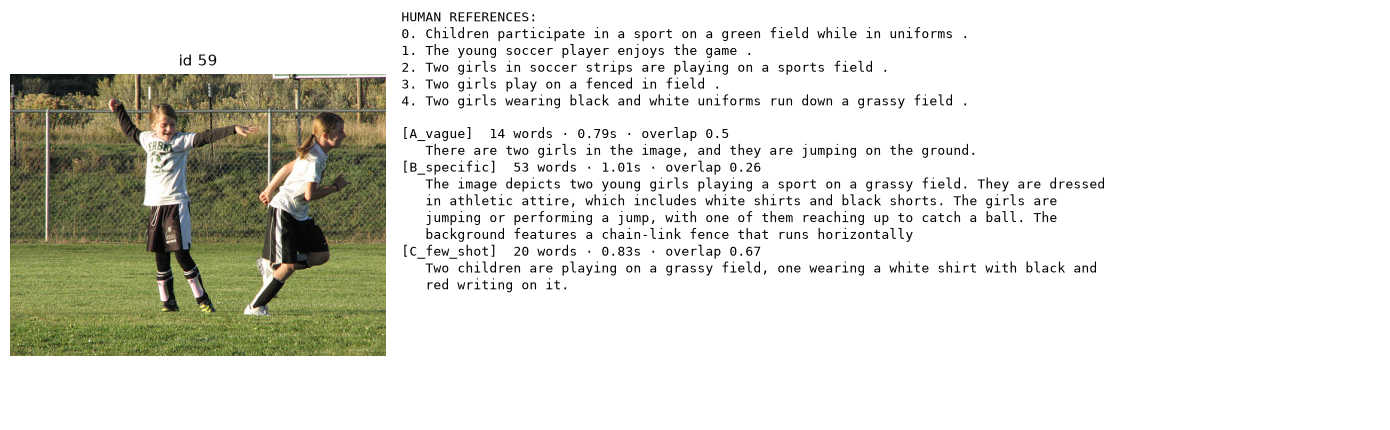

In [48]:
def show_prompt_comparison(s, df):
    """One row per image: thumbnail | 5 human references + the 3 technique answers."""
    # Two panels side by side: small image on the left, wider text panel on the right
    fig, (ax_img, ax_txt) = plt.subplots(
        1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 2.6]}
    )
    ax_img.imshow(s["image"]); ax_img.axis("off")
    ax_img.set_title(f"id {s['id']}", fontsize=11)

    # Wrap long text at ~86 characters and indent continuation lines
    wrap = lambda t, w=86: "\n".join(textwrap.wrap(t, w)).replace("\n", "\n   ")

    # Build the text panel: all 5 human references first...
    lines = ["HUMAN REFERENCES:"]
    lines += [f"{k}. {wrap(c)}" for k, c in enumerate(s["captions"])]
    lines.append("")
    # ...then each technique's answer with its length, time, and overlap score
    for _, r in df[df.id == s["id"]].iterrows():
        lines.append(f"[{r.technique}]  {r.words} words · {r.time_s}s · overlap {r.overlap}")
        lines.append("   " + wrap(r.answer))

    # transAxes = coordinates 0-1 within the panel, so (0, 1) is its top-left corner
    ax_txt.text(0, 1, "\n".join(lines), va="top", ha="left", fontsize=9.5,
                family="monospace", transform=ax_txt.transAxes)
    ax_txt.axis("off")
    plt.tight_layout(); plt.show()

# Show every held-out image with its references and the 3 answers, one after another
for s in eval_set:
    show_prompt_comparison(s, prompt_df)

### Manual judgements
`correct`: **Y** = main subject and action right · **partial** = subject right, a detail wrong or invented · **N** = wrong subject or scene.  
`hallucination`: **Y**es or **N**o.

In [49]:
# Manual judgements, filled in after viewing the comparison above.
# Each entry: (correct, hallucination)
#   correct:       "Y" / "partial" / "N"
#   hallucination: "Y" (model invented something) / "N"
manual_prompts = {
    #     A_vague          B_specific       C_few_shot
    50: [("Y", "N"),        ("P", "N"),        ("N", "Y")],
    51: [("P", "N"),        ("Y", "N"),        ("P", "Y")],
    52: [("Y", "N"),        ("Y", "N"),        ("Y", "N")],
    53: [("P", "N"),        ("P", "N"),        ("P", "N")],
    54: [("Y", "N"),        ("P", "Y"),        ("N", "Y")],
    55: [("Y", "N"),        ("P", "Y"),        ("N", "Y")],
    56: [("P", "N"),        ("Y", "N"),        ("N", "Y")],
    57: [("P", "N"),        ("Y", "N"),        ("Y", "N")],
    58: [("Y", "N"),        ("Y", "N"),        ("Y", "N")],
    59: [("P", "N"),        ("Y", "N"),        ("P", "Y")],
}
# Copy each label into the matching (image id, technique) row of the results table.
# zip(PROMPTS, labels) pairs the technique names (in PROMPTS order) with the 3 tuples per image.
for img_id, labels in manual_prompts.items():
    for tech, (c, h) in zip(PROMPTS, labels):
        mask = (prompt_df.id == img_id) & (prompt_df.technique == tech)   # select one row
        prompt_df.loc[mask, ["correct", "hallucination"]] = [c, h]

prompt_df.to_csv("eval_results.csv", index=False)   # full results incl. words + overlap

# Mean inference time per technique
print(prompt_df.groupby("technique").time_s.mean().round(2).to_string())

# Final results table: one row per (image, technique)
prompt_df[["id", "technique", "answer", "time_s", "correct", "hallucination"]]

technique
A_vague       0.79
B_specific    0.91
C_few_shot    0.80


,id,technique,answer,time_s,correct,hallucination
0,50,A_vague,There is a person performing a stunt in the image.,0.86,Y,N
1,50,B_specific,The main subject is a man performing on a water slide.,0.79,P,N
2,50,C_few_shot,This man is in the water and is being pulled by a person with straps.,0.80,N,Y
3,51,A_vague,"There are people in the image, and they are swimming in the water.",0.80,P,N
4,51,B_specific,In this image there is a girl in the foreground who is standing and smiling. In the background there is water and there are two persons in the water.,0.89,Y,N
5,51,C_few_shot,A girl in a floral swimsuit is smiling as she walks towards the ocean.,0.81,P,Y
6,52,A_vague,"There is a girl in the image, and she is running.",0.79,Y,N
7,52,B_specific,The main subject in the image is a small girl. She appears to be running or jumping.,0.83,Y,N
8,52,C_few_shot,A girl is running in the grass with her hair blowing in the wind.,0.82,Y,N
9,53,A_vague,"There are people in the image, and they are riding on a ride.",0.80,P,N


## Analysis

Overall, the model understood the main subject of most images well, but often omitted or got smaller details wrong. The vague zero-shot prompt (A) was the safest: 5/10 correct, 5 partial, and no hallucinations, though its answers were generic ("There is a person walking in the image.") and don't tell us the important details we are interested in. The specific prompt (B) was the most accurate (6/10 correct, 0 wrong), but it ignored "one sentence" and averaged 34 words, adding invented details such as a skateboard (id 55). Few-shot prompting (C) performed worst, with 4 wrong answers and 6 hallucinations. On image 56, it said a man was "playing in the sand at the beach" when he was pointing at a car in a parking lot. That phrase was copied from one of the few-shot examples, so the model imitated the examples' content rather than their style. Inference time was similar across prompts (0.79–0.91 s on Apple MPS), because time grows with the number of generated tokens rather than prompt length. B was slowest only because its answers were longest. Overall, the results are reasonable for a 256M-parameter open-weight model, which is small compared with most production VLMs.